# P2.07 — Synthesis: how much does each explanation account for?

**Questions:** RQ3.6 (do demand changes explain regional differences in price growth?) and RQ5.4 (can the drivers
be separated?), with one view across the whole phase.

P2.01 to P2.06 each tested one explanation. Here they enter **one cross-section** of the mainland municipalities,
outcome the log change of price-to-income 2016 to 2024, in blocks:
* **Geography:** district, coast class, density class (P2.04);
* **Demand:** foreign residents and other population change 2016 to 2023 (% of the 2016 population, P2.02) and
  household growth 2011 to 2021 (P2.05);
* **Supply:** dwelling growth 2011 to 2021 (P2.05) and completions 2017 to 2023 per 1,000 dwellings (P2.02);
* **Tourism:** registered short-term rentals per 1,000 dwellings (P2.02);
* **Second homes:** secondary-residence share 2021 (P2.06).

The question is how much of the variation across municipalities each block accounts for, not a causal ranking:
blocks overlap (dense coastal places also gain foreign residents) and the order they are added in matters, so
the ladder is also run in the reverse order.

In [1]:
import numpy as np
import pandas as pd

from pthousing.analysis import descriptive as desc
from pthousing.analysis import supply
from pthousing.data import build_panel, typology
from pthousing.viz import charts, style

style.apply_style()
panel = build_panel.read("panel_municipality_year")
stock = supply.read_stock()
ty = typology.read().set_index("muni_code")
frame = supply.synthesis_frame(panel, stock, ty)
print(frame.shape, frame["dlog_pti"].notna().sum(), "with an outcome")
print(frame.describe().round(2).T.to_string())

(278, 12) 271 with an outcome
                       count   mean    std    min    25%    50%    75%     max
dlog_pti               271.0   0.17   0.29  -0.94  -0.01   0.17   0.37    0.87
foreign_change_pct     278.0   4.01   4.57  -1.41   1.19   2.58   5.31   36.07
other_pop_change_pct   278.0  -1.51   6.83 -20.68  -5.99  -1.22   2.72   31.57
households_change_pct  278.0  -1.46   6.40 -17.46  -6.46  -1.75   3.69   14.96
dwellings_change_pct   278.0   1.76   2.58  -9.93   0.23   1.70   3.37   11.98
completions_per_1000   278.0  15.92  11.25   0.86   7.26  13.33  20.52   56.47
rentals_per_1000       278.0  16.36  31.04   0.46   4.01   7.92  13.41  236.12
secondary_2021_pct     278.0  26.85  13.56   4.17  14.21  26.28  37.52   58.23


## Step 1 — Variance explained, block by block

                                             block    r2  r2_adj  r2_added  n_obs
              Geography (district, coast, density) 0.530   0.490     0.530    271
Demand (foreign residents, population, households) 0.538   0.493     0.008    271
                   Supply (dwellings, completions) 0.543   0.495     0.005    271
                      Tourism (short-term rentals) 0.545   0.494     0.001    271
                                      Second homes 0.547   0.494     0.002    271


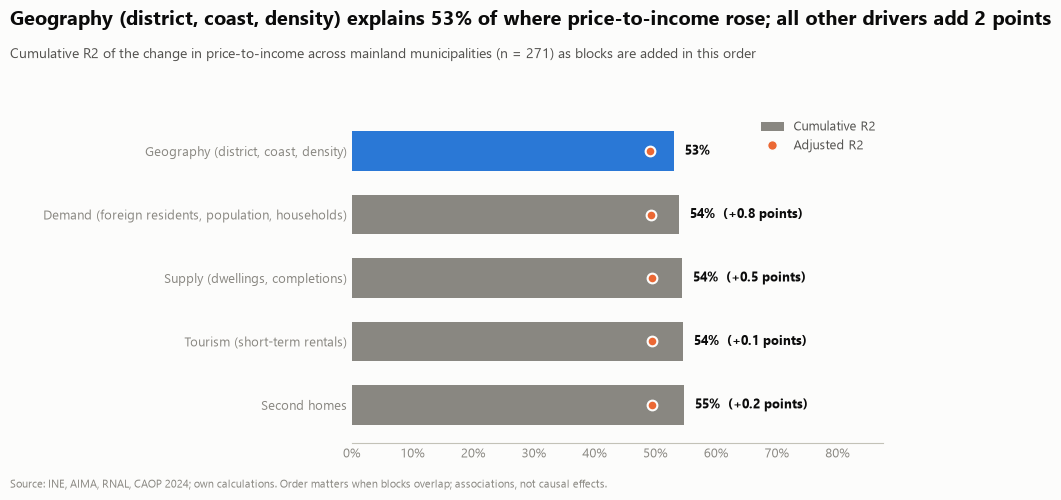

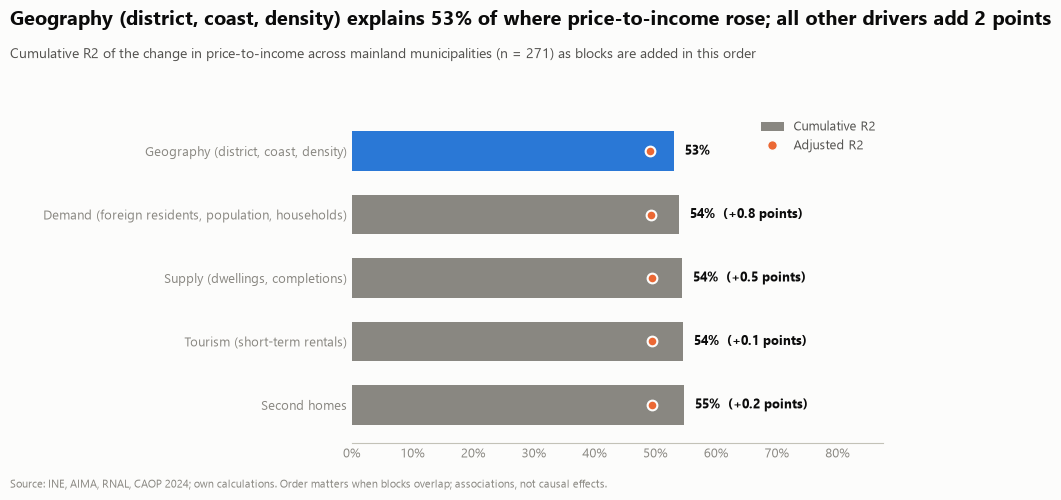

In [2]:
GEO = ["C(district)", "C(coast_class)", "C(density_class)"]
DEMAND = ["foreign_change_pct", "other_pop_change_pct", "households_change_pct"]
SUPPLY = ["dwellings_change_pct", "completions_per_1000"]
TOURISM = ["rentals_per_1000"]
SECOND = ["secondary_2021_pct"]
BLOCKS = {
    "Geography (district, coast, density)": GEO,
    "Demand (foreign residents, population, households)": DEMAND,
    "Supply (dwellings, completions)": SUPPLY,
    "Tourism (short-term rentals)": TOURISM,
    "Second homes": SECOND,
}
ladder = desc.block_r2(frame, "dlog_pti", BLOCKS)
style.save_table(ladder, "p2", "synthesis_r2_ladder")
print(ladder.round(3).to_string(index=False))
fig = charts.r2_ladder(ladder, "price-to-income")
style.save_fig(fig, "p2", "synthesis_r2_ladder")
fig

**Finer geography and the reverse order.** District alone, then the classes; and the drivers first, geography last.

In [3]:
fine = desc.block_r2(
    frame,
    "dlog_pti",
    {"District": ["C(district)"], "+ coast and density class": GEO[1:]},
)
reverse = desc.block_r2(
    frame,
    "dlog_pti",
    {
        "Demand": DEMAND, "+ supply": SUPPLY, "+ tourism": TOURISM, "+ second homes": SECOND,
        "+ geography": GEO,
    },
)  # fmt: skip
style.save_table(
    pd.concat([fine.assign(order="geography"), reverse.assign(order="drivers first")]),
    "p2",
    "synthesis_r2_order_check",
)
print(fine.round(3).to_string(index=False))
print(reverse.round(3).to_string(index=False))

                    block    r2  r2_adj  r2_added  n_obs
                 District 0.433   0.395     0.433    271
+ coast and density class 0.530   0.490     0.097    271
         block    r2  r2_adj  r2_added  n_obs
        Demand 0.292   0.284     0.292    271
      + supply 0.318   0.305     0.026    271
     + tourism 0.320   0.305     0.002    271
+ second homes 0.350   0.333     0.030    271
   + geography 0.547   0.494     0.196    271


## Step 2 — What survives in one model? (per standard deviation)
All drivers together, with district intercepts and then with coast and density class, HC3 errors; the
coefficient is the % change in price-to-income associated with one standard deviation of the driver.

In [4]:
drivers = [*DEMAND, *SUPPLY, *TOURISM, *SECOND]
models = pd.concat(
    [
        supply.associations(frame, "dlog_pti", drivers, fixed_effects="district", label="Same district"),
        supply.associations(
            frame, "dlog_pti", drivers, fixed_effects="district",
            categorical=["coast_class", "density_class"], label="Same district, coast and density",
        ),
    ],
    ignore_index=True,
)  # fmt: skip
models["pct_per_sd"] = 100 * np.expm1(models["coef_per_sd"])
style.save_table(models, "p2", "synthesis_joint_model")
print(
    models[["spec", "term", "coef", "p", "pct_per_sd", "n_obs", "r2"]]
    .round(3)
    .to_string(index=False)
)
print(frame[drivers].corr().round(2).to_string())

                            spec                  term   coef     p  pct_per_sd  n_obs    r2
                   Same district    foreign_change_pct  0.012 0.107       5.880    271 0.501
                   Same district  other_pop_change_pct  0.003 0.545       1.880    271 0.501
                   Same district households_change_pct  0.006 0.222       4.205    271 0.501
                   Same district  dwellings_change_pct -0.013 0.086      -3.191    271 0.501
                   Same district  completions_per_1000  0.002 0.294       1.751    271 0.501
                   Same district      rentals_per_1000 -0.000 0.500      -1.481    271 0.501
                   Same district    secondary_2021_pct -0.002 0.139      -3.055    271 0.501
Same district, coast and density    foreign_change_pct  0.008 0.213       3.532    271 0.547
Same district, coast and density  other_pop_change_pct  0.001 0.745       0.914    271 0.547
Same district, coast and density households_change_pct  0.001 0.770   

## Findings

1. **Geography accounts for most of where affordability worsened (RQ3.6).** District, coast class and density
   class explain 53% of the variation in the change of price-to-income across 271 mainland municipalities
   (district alone 43%, the classes add 9.7 points). Demand, supply, tourism and second homes added together add
   1.7 points (0.8, 0.5, 0.1, 0.2); adjusted R2 does not move (49.0% to 49.4%).
2. **The drivers are mostly the geography seen another way.** Alone, demand explains 29% and all the drivers 35%,
   but added after the drivers geography still adds 19.6 points: places that gained foreign residents, households
   and dwellings are the dense coastal ones, so the two cannot be separated with these data. Demand, supply and
   second homes are correlated with each other (0.4 to 0.7 for population, households, completions).
3. **Within a region nothing stands out in one model.** With district intercepts, one standard deviation of
   foreign-resident change goes with +5.9% (p = 0.11), dwelling growth with −3.2% (p = 0.09) and second homes with
   −3.1% (p = 0.14); with coast and density class added all fall to between −2.3% and +3.5% (p ≥ 0.18). Each was
   significant on its own in P2.02, P2.05 and P2.06: the single-driver results partly measure one another.

**What this does and does not say.** The drivers explain little *beyond where a municipality is*, not that they do
not matter: a desirable place draws people, foreign residents and construction and sees prices rise, so place
and driver move together, and 271 municipalities and a single 2016 to 2024 change are too little variation to
separate them. The panel regressions of P2.02 use changes within a municipality over time and find the same
order of magnitude (drivers explain 1.6% to 6.8% of the within variation). A causal answer needs a design with a
credible comparison, which is the aim of phase 3.